In [1]:
import os
import sys
import numpy as np

module_path = os.path.abspath(os.path.join('..', ''))
if module_path not in sys.path:
    sys.path.append(module_path)

from rect_prune_ood.lib.util.paths import get_top_level_path

results_dir = os.path.join(get_top_level_path(), 'results')
imagenet_c_results_dir = os.path.join(results_dir, 'imagenet', "baseline", "imagenet_c")
ablation_study_results_dir = os.path.join(results_dir, 'ablation_study_pertubation')
os.makedirs(ablation_study_results_dir, exist_ok=True)

perturbation_order = [
    "spatter",
    "elastic_transform",
    "gaussian_blur",
    "saturate",
    "zoom_blur",
    "defocus_blur",
    "brightness",
    "jpeg_compression",
    "shot_noise",
    "gaussian_noise",
    "motion_blur",
    "speckle_noise",
    "impulse_noise",
    "pixelate",
    "contrast",
    "frost",
    "fog",
    "glass_blur",
    "snow"
]

imagenet_c_perturbations_all = [
        "brightness",
        "defocus_blur",
        "fog",
        "gaussian_blur",
        "glass_blur",
        "jpeg_compression",
        "pixelate",
        "shot_noise",
        "spatter",
        "zoom_blur",
        "contrast",
        "elastic_transform",
        "frost",
        "gaussian_noise", 
        "impulse_noise",
        "motion_blur",
        "saturate",
        "snow",
        "speckle_noise"
    ]

In [2]:
from torch.nn import Module
from torch import Tensor


class APESP(Module):
    def __init__(self, mask) -> None:
        #super(LayerScaler, self).__init__()
        super(APESP, self).__init__()
        self.mask = mask
        
    
    def forward(self, x: Tensor) -> Tensor:
        x = self.apes_p(x)
        return x
    
    def apes_p(self, x):
        assert x.dim() == 4
        _, c, _, _ = x.shape
        assert self.mask.shape[0] == c 

        x = x * self.mask

        return x

In [3]:
imagenet_c_activations = np.load(os.path.join(imagenet_c_results_dir, "imagenet_c_activations_severity_5.npy"))
imagenet_activations = np.load(os.path.join(results_dir, 'imagenet', 'baseline', 'imagenet_activations.npy'))
imagenet_activations = np.transpose(imagenet_activations)

In [4]:
import torch
from lightning import Trainer
from rect_prune_ood.lib.experiments.feature_extractor import FeatureExtractor
from rect_prune_ood.lib.experiments.backbones import get_resnet50
from rect_prune_ood.lib.experiments.pipeline import Pipeline
from rect_prune_ood.lib.util.data_loader import get_data_loader

#for i in range(len(imagenet_c_pertubations)):
for i in range(len(perturbation_order)):

    perturbation_index = []
    for j in range(i + 1):
        perturbation_index.append(imagenet_c_perturbations_all.index(perturbation_order[j]))

    activations = np.concatenate([imagenet_c_activations[j] for j in perturbation_index], axis=1)

    variance = np.var(activations, axis=1)
    variance = torch.tensor(variance)

    percentile = np.percentile(variance, 85)

    mask = torch.where(variance <= percentile, 1, 0)
    mask = mask.view(variance.shape[0], 1, 1).cuda()


    #################
    ### ImageNet ####
    #################
    
    feature_extractor = FeatureExtractor(get_resnet50(), 'avgpool')
    
    fc_layer = feature_extractor.get_fc_layer()

    pipeline = Pipeline(feature_extractor, 'baseline', fc_layer, caputure_activations=False)
    pipeline.method_list = [APESP(mask)]

    dataloader, _ = get_data_loader('imagenet', batch_size=16)

    # Trainer
    trainer = Trainer(logger=None)
    trainer.test(pipeline, dataloader)

    results = pipeline.results

    np.save(os.path.join(ablation_study_results_dir, f"as_pertubations_imagenet_{i+1}.npy"), results)

    ####################
    ### OpenImage-O ####
    ####################

    feature_extractor = FeatureExtractor(get_resnet50(), 'avgpool')
    
    fc_layer = feature_extractor.get_fc_layer()

    pipeline = Pipeline(feature_extractor, 'baseline', fc_layer, caputure_activations=False)
    pipeline.method_list = [APESP(mask)]

    dataloader, _ = get_data_loader('openimage-o', batch_size=16)

    # Trainer
    trainer = Trainer(logger=None)
    trainer.test(pipeline, dataloader)

    results = pipeline.results

    np.save(os.path.join(ablation_study_results_dir, f"as_pertubations_openimage-o_{i+1}.npy"), results)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/visinf/home/vilab17/miniforge3/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/logger_connector/logger_connector.py:75: Starting from v1.9.0, `tensorboardX` has been removed as a dependency of the `lightning.pytorch` package, due to potential conflicts with other packages in the ML ecosystem. For this reason, `logger=True` will use `CSVLogger` as the default logger, unless the `tensorboard` or `tensorboardX` packages are found. Please `pip install lightning[extra]` or one of them to enable TensorBoard support by default
You are using a CUDA device ('NVIDIA GeForce RTX 3080 Ti') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.s

Testing: |          | 0/? [00:00<?, ?it/s]

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Testing: |          | 0/? [00:00<?, ?it/s]

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Testing: |          | 0/? [00:00<?, ?it/s]

... (66 outputs left out)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Testing: |          | 0/? [00:00<?, ?it/s]

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Testing: |          | 0/? [00:00<?, ?it/s]

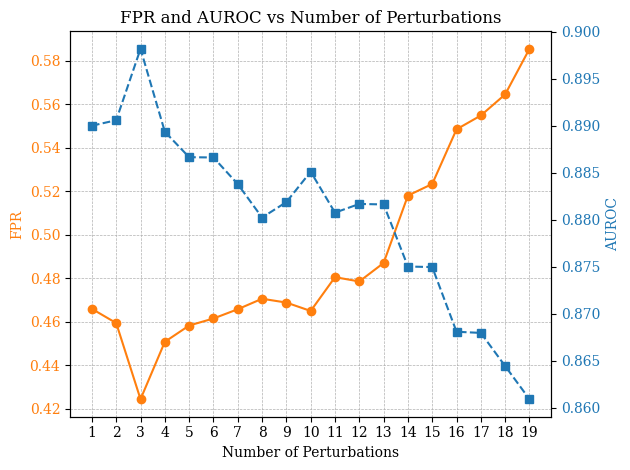

In [5]:
from rect_prune_ood.lib.eval.metrics import *

import csv

all_results = []

for i in range(len(imagenet_c_perturbations_all)):

    imagenet_scores = np.load(os.path.join(ablation_study_results_dir, f"as_pertubations_imagenet_{i+1}.npy"), allow_pickle=True).item()["energy_score"]
    openimage_o_scores = np.load(os.path.join(ablation_study_results_dir, f"as_pertubations_openimage-o_{i+1}.npy"), allow_pickle=True).item()["energy_score"]

    results = cal_metric(imagenet_scores, openimage_o_scores)
    results["num_perturbations"] = i + 1

    all_results.append(results)

csv_filename = os.path.join(ablation_study_results_dir, "as_num_perturbations_results.csv")
with open(csv_filename, mode='w', newline='') as file:
    writer = csv.DictWriter(file, fieldnames=["num_perturbations", "FPR", "AUROC"])
    writer.writeheader()
    for results in all_results:
        writer.writerow({
            "num_perturbations": results["num_perturbations"],
            "FPR": results["FPR"],
            "AUROC": results["AUROC"]
        })

plt.rcParams.update({
    "text.usetex": False,
    "font.family": "serif"
})

# Plot results
num_perturbations = [res["num_perturbations"] for res in all_results]
fpr_values = [res["FPR"] for res in all_results]
auroc_values = [res["AUROC"] for res in all_results]

fig, ax1 = plt.subplots()

# Left y-axis for FPR
ax1.set_xlabel("Number of Perturbations")
ax1.set_ylabel("FPR", color="tab:orange")
ax1.plot(num_perturbations, fpr_values, marker='o', linestyle='-', color="tab:orange", label="FPR")
ax1.tick_params(axis='y', labelcolor="tab:orange")
ax1.set_xticks(num_perturbations)  # Show all perturbation values on x-axis
ax1.grid(True, which='both', linestyle='--', linewidth=0.5)

# Right y-axis for AUROC
ax2 = ax1.twinx()
ax2.set_ylabel("AUROC", color="tab:blue")
ax2.plot(num_perturbations, auroc_values, marker='s', linestyle='--', color="tab:blue", label="AUROC")
ax2.tick_params(axis='y', labelcolor="tab:blue")

plt.title("FPR and AUROC vs Number of Perturbations")
fig.tight_layout()
pdf_path = os.path.join(ablation_study_results_dir, "num_perturbations_fpr_auroc_plot.pdf")
plt.savefig(pdf_path, format="pdf")
plt.show()